# Notebook 3 of 3: Team Scouting Tool
## Can a Defense Predict Run vs. Pass Before the Snap? (2025 NFL Season)

| Notebook | What it does |
|---|---|
| 01_data_cleaning_eda | Loads the 2025 data, cleans it, explores which pre-snap factors relate to run vs. pass, and saves a clean file |
| 02_league_model | Trains, tunes, and tests league-wide models against baselines and xpass, and checks whether one-team models are worth it |
| **03_team_scouting_tool** (this one) | Pick an opponent and the weeks of film you have, and get a call sheet for the next game |

**Who this is for:** a defensive coach preparing for one opponent.

**How it works:** type the opponent and the weeks you have film on (for example `1-3` before a week 4 game). Everything in this notebook uses **only those weeks**, exactly what a coach would have before the game.

**What you get:** tendency charts and a printable **call sheet** that shows where this opponent breaks from the league average.

*How accurate is this approach? That is tested in Notebook 2, Sections 19-20.*

## 1. Setup

In [1]:
from pathlib import Path          # builds the path to the data folder
import re                         # reads the week range the user types (e.g., "1-3")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid")  # light grid makes bar heights easier to read

In [12]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/capstone/data")
except ImportError:
    DATA_DIR = Path("data")

# Load the clean file saved at the end of Notebook 1
pbp_2025 = pd.read_csv("/content/pbp_2025_clean.csv")
print(f"Loaded {len(pbp_2025):,} plays x {pbp_2025.shape[1]} columns")

# Features the defense knows before making its call (same list as Notebook 2)
FEATURES = [
    "is_home", "div_game", "down", "ydstogo", "yardline_100", "goal_to_go",
    "game_seconds_remaining", "half_seconds_remaining", "score_differential",
    "posteam_timeouts_remaining", "defteam_timeouts_remaining",
    "no_huddle",   # tempo is visible before the snap
    # n_rb is left out on purpose: each personnel coefficient means "swap one RB for this"
    "n_te", "n_wr", "n_ol",
]

Mounted at /content/drive
Loaded 34,486 plays x 32 columns


### Helpers (run once; defines functions, prints nothing)

In [13]:
# ---------- Down & distance buckets (display order for charts) ----------
DD_ORDER = (
    ["1st & 10", "1st & 11+", "1st & 6-9", "1st & 1-5"]
    + [f"{d} & {r}" for d in ["2nd", "3rd", "4th"] for r in ["10+", "7-9", "4-6", "1-3"]]
)

def parse_week_range(text):
    """Turn what the user types ("1-3", "weeks 1 - 3", "5") into (first week, last week)."""
    nums = [int(n) for n in re.findall(r"\d+", text)]   # pull out every number typed
    if len(nums) == 1:                                   # one number = a one-week range
        return nums[0], nums[0]
    if len(nums) == 2 and nums[0] <= nums[1]:
        return nums[0], nums[1]
    raise ValueError(f"Could not read a week range from '{text}'. Try something like 1-3.")


def acc_margin(acc, n):
    """95% margin of error for an accuracy measured on n plays.
    Example: 0.70 on 63 plays is about +/- 0.11, so small gaps between models are noise."""
    return 1.96 * np.sqrt(acc * (1 - acc) / n) if n > 0 else np.nan

DOWN_ORDER = ["1st down", "2nd down", "3rd down", "4th down"]
COLORS = {"Baseline": "#9e9e9e", "xpass": "#9467bd", "Logistic Regression": "#1f77b4",
          "Decision Tree": "#2ca02c", "KNN": "#ff7f0e"}

# ---------- Chart: pass/run % stacked by group (steps 3-4) ----------
def plot_pass_run_by_group(group_col, order, title):
    # Training weeks only: a coach scouting the next game can't see that game's plays
    g = train.groupby(group_col)["pass_play"].agg(["mean", "count"]).reindex(order).dropna()
    pass_pct = g["mean"] * 100
    run_pct = 100 - pass_pct
    labels = [f"{i}\n(n={int(n)})" for i, n in zip(g.index, g["count"])]
    fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(g)), 5))
    x = np.arange(len(g))
    ax.bar(x, pass_pct, color="#1f77b4", label="Pass")
    ax.bar(x, run_pct, bottom=pass_pct, color="#ff7f0e", label="Run")
    for i, p in enumerate(pass_pct):
        ax.text(i, p / 2, f"{p:.0f}%", ha="center", va="center", color="white", fontsize=9)
    ax.axhline(team_pass_pct, color="black", linestyle="--", linewidth=1,
               label=f"{team} overall pass % ({team_pass_pct:.0f}%)")
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_ylabel("% of plays"); ax.set_ylim(0, 100); ax.set_title(f"{title} (weeks {TRAIN_LABEL})")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3)
    plt.tight_layout(); plt.show()


# ---------- Extra situations for the call sheet ----------
def add_situations(df):
    """Label each play by score, field position, clock, and tempo, so they can be grouped."""
    df = df.copy()
    df["score"] = pd.cut(df["score_differential"], [-100, -9, -1, 0, 8, 100],
                         labels=["Trailing by 9+", "Trailing by 1-8", "Tied", "Leading by 1-8", "Leading by 9+"])
    df["field"] = pd.cut(df["yardline_100"], [0, 20, 50, 100],
                         labels=["Red zone (inside 20)", "Opponent territory (21-50)", "Own territory"])
    df["clock"] = np.where(df["half_seconds_remaining"] <= 120, "Last 2 min of a half", "Rest of the game")
    df["tempo"] = np.where(df["no_huddle"] == 1, "No-huddle", "Huddle")
    return df


def read(pass_pct, plays, min_n=5):
    """Plain-language read for a coach."""
    if plays < min_n:
        return "small sample"
    if pass_pct >= 65:
        return "LEAN PASS"
    if pass_pct <= 35:
        return "LEAN RUN"
    return "toss-up"


def tendency_table(group_col, order=None, min_n=5):
    """Team pass % vs league pass % (same weeks) for each group, with a plain-language read."""
    t = train.groupby(group_col, observed=True)["pass_play"].agg(Plays="size", team="mean")
    lg = league_train.groupby(group_col, observed=True)["pass_play"].mean().rename("league")
    tab = t.join(lg)
    if order is not None:
        tab = tab.reindex([o for o in order if o in tab.index])
    tab["Pass %"] = (tab["team"] * 100).round(0)
    tab["League pass %"] = (tab["league"] * 100).round(0)
    tab["vs league"] = (tab["Pass %"] - tab["League pass %"]).map(lambda d: f"{d:+.0f}")
    tab["Read"] = [read(p, n, min_n) for p, n in zip(tab["Pass %"], tab["Plays"])]
    tab.index.name = None
    return tab[["Plays", "Pass %", "League pass %", "vs league", "Read"]]

## 2. Choose the Opponent and the Film Weeks

`TEAM` and `WEEK_RANGE` are set to the Rams, weeks 1-3, so **Restart & Run All** finishes without stopping. Set either one to `None` to type your own.

**Week range:** `1-3` means you have film on weeks 1-3 and are preparing for the opponent's next game.

In [14]:
# Set these to skip the prompts (handy for Restart & Run All); set to None to type them in
TEAM = "LA"          # the opponent you are scouting (the Rams are "LA", the Chargers "LAC")
WEEK_RANGE = "1-3"   # the weeks you have film on

# Show the valid team abbreviations
valid_teams = sorted(pbp_2025["posteam"].unique())
print("Valid teams:", ", ".join(valid_teams))

# Ask for a team and keep asking until it is a valid abbreviation
team = TEAM.strip().upper() if TEAM else input("Enter a team abbreviation (e.g., LA, SF, KC): ").strip().upper()
while team not in valid_teams:
    team = input(f"'{team}' is not valid. Enter a team abbreviation: ").strip().upper()

# This team's own offensive plays (is_home, pass_play, dd_bucket, personnel come from Notebook 1)
team_df = pbp_2025[pbp_2025["posteam"] == team].copy()
team_weeks = sorted(team_df["week"].unique())
print(f"\n{team} played weeks: {', '.join(str(w) for w in team_weeks)}")

# Ask for the film weeks until at least one game falls inside the range
text = WEEK_RANGE if WEEK_RANGE else input("Enter the film weeks (e.g., 1-3): ")
while True:
    try:
        first, last = parse_week_range(text)
        train_weeks = [w for w in team_weeks if first <= w <= last]   # byes inside the range are skipped
        if not train_weeks:
            raise ValueError(f"{team} played no games in weeks {first}-{last}.")
        break
    except ValueError as err:
        text = input(f"{err} Enter the film weeks again (e.g., 1-3): ")

TRAIN_LABEL = f"{first}-{last}" if first != last else f"{first}"
later_games = [w for w in team_weeks if w > last]
NEXT_WEEK = later_games[0] if later_games else last + 1    # the game the coach is preparing for

# Film = this team's plays in those weeks; league = every team's plays in the same weeks
train = add_situations(team_df[team_df["week"].isin(train_weeks)])
league_train = add_situations(pbp_2025[pbp_2025["week"].between(first, last)])
team_pass_pct = train["pass_play"].mean() * 100

# Most common personnel groups first (used to order the charts)
PERS_ORDER = train["personnel"].value_counts().index.tolist()

print(f"\nScouting {team} for week {NEXT_WEEK} using film from weeks {TRAIN_LABEL} "
      f"({len(train_weeks)} games, {len(train)} plays)")
if len(train) < 150:
    print("\u26a0\ufe0f Fewer than 150 plays of film: many situations will have very few plays.")

Valid teams: ARI, ATL, BAL, BUF, CAR, CHI, CIN, CLE, DAL, DEN, DET, GB, HOU, IND, JAX, KC, LA, LAC, LV, MIA, MIN, NE, NO, NYG, NYJ, PHI, PIT, SEA, SF, TB, TEN, WAS

LA played weeks: 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21

Scouting LA for week 4 using film from weeks 1-3 (3 games, 177 plays)


## 3. Run/Pass %

The opponent's pass % in the film weeks, next to the league over the same weeks.

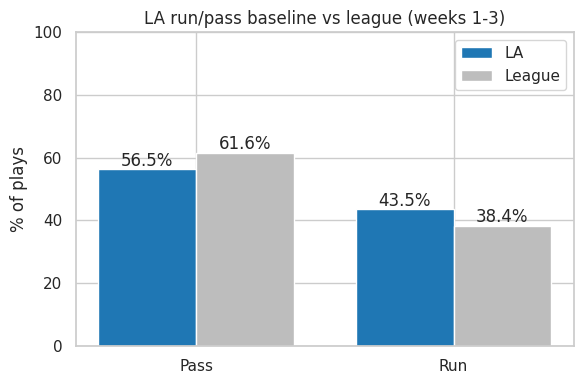

In [15]:
# League over the same weeks, so both bars describe the same stretch of the season
league_pass_pct = league_train["pass_play"].mean() * 100
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(2); w = 0.38
ax.bar(x - w / 2, [team_pass_pct, 100 - team_pass_pct], w, label=team, color="#1f77b4")
ax.bar(x + w / 2, [league_pass_pct, 100 - league_pass_pct], w, label="League", color="#bdbdbd")
for i, (a, b) in enumerate(zip([team_pass_pct, 100 - team_pass_pct], [league_pass_pct, 100 - league_pass_pct])):
    ax.text(i - w / 2, a + 1, f"{a:.1f}%", ha="center"); ax.text(i + w / 2, b + 1, f"{b:.1f}%", ha="center")
ax.set_xticks(x); ax.set_xticklabels(["Pass", "Run"]); ax.set_ylim(0, 100)
ax.set_ylabel("% of plays"); ax.set_title(f"{team} run/pass baseline vs league (weeks {TRAIN_LABEL})"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Run/Pass % by Down & Distance

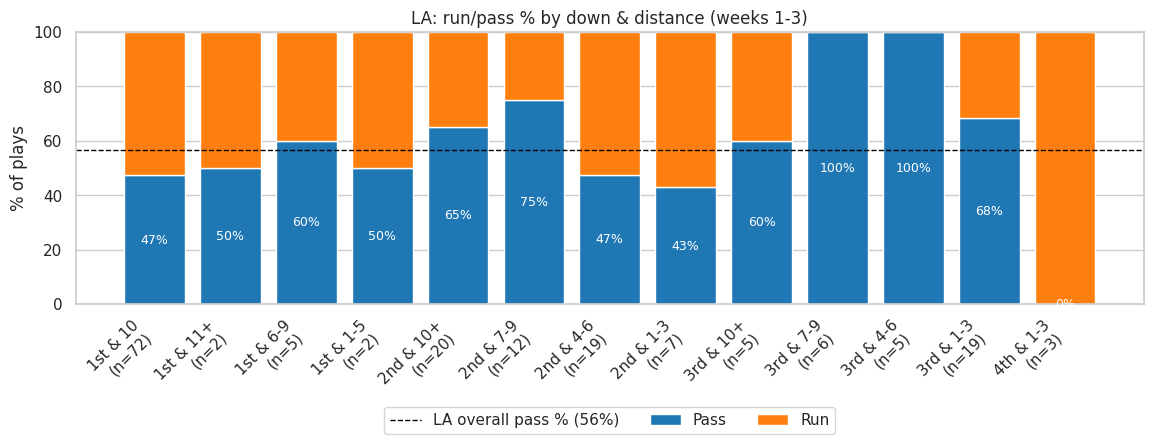

In [16]:
plot_pass_run_by_group("dd_bucket", DD_ORDER, f"{team}: run/pass % by down & distance")

## 5. Run/Pass % by Personnel

Personnel groups count RB + FB as backs. A 6th lineman gets a `+ 6 OL` tag.

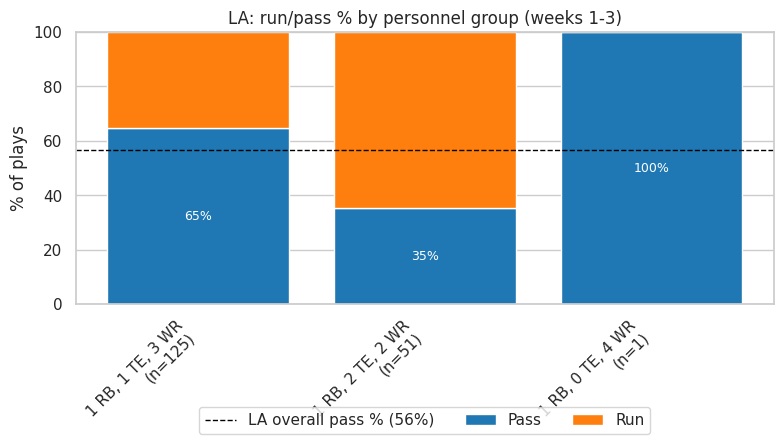

In [17]:
plot_pass_run_by_group("personnel", PERS_ORDER, f"{team}: run/pass % by personnel group")

## 6. Pass % by Down & Distance + Personnel

Heatmap of pass % (cell text = pass %, n). Gray cells have no plays.

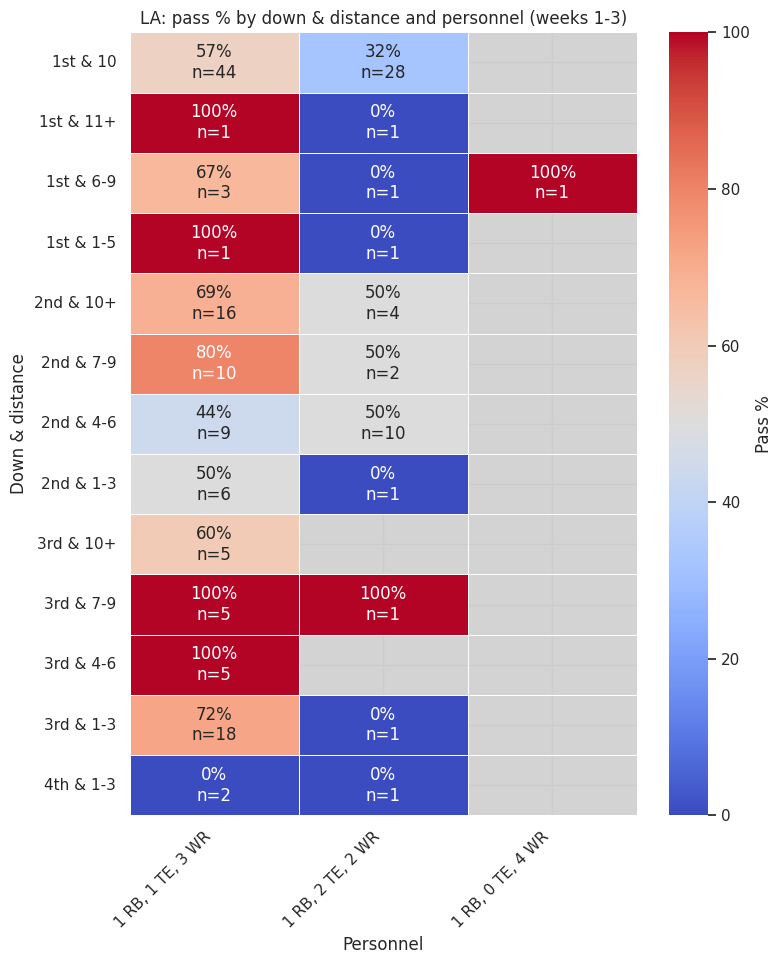

In [18]:
# Training weeks only, so the heatmap describes what a coach could scout
pct = train.pivot_table(index="dd_bucket", columns="personnel", values="pass_play", aggfunc="mean") * 100
cnt = train.pivot_table(index="dd_bucket", columns="personnel", values="pass_play", aggfunc="count")
rows = [r for r in DD_ORDER if r in pct.index]
pct, cnt = pct.reindex(index=rows, columns=PERS_ORDER), cnt.reindex(index=rows, columns=PERS_ORDER)
annot = pct.copy().astype(object)
for r in pct.index:
    for c in pct.columns:
        annot.loc[r, c] = "" if np.isnan(pct.loc[r, c]) else f"{pct.loc[r, c]:.0f}%\nn={int(cnt.loc[r, c])}"
fig, ax = plt.subplots(figsize=(max(8, 1.4 * len(PERS_ORDER)), 0.6 * len(rows) + 2))
ax.set_facecolor("lightgray")
sns.heatmap(pct, annot=annot, fmt="", cmap="coolwarm", center=50, vmin=0, vmax=100,
            cbar_kws={"label": "Pass %"}, linewidths=0.5, ax=ax)
ax.set_xlabel("Personnel"); ax.set_ylabel("Down & distance")
ax.set_title(f"{team}: pass % by down & distance and personnel (weeks {TRAIN_LABEL})")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

## 7. Personnel Tells

Personnel is the one clue a defense sees **before** its call, because substitutions run onto the field before the huddle breaks. A logistic regression on the film weeks measures what each swap does to the odds of a pass, **with down, distance, score, and clock held fixed**.

- Odds ratio above 1 = the swap makes a pass more likely. Below 1 = a run is more likely.
- If the team never changed its RB count, TE and WR only traded with each other, so the swap is read as WR for TE.

In [19]:
# Logistic regression on the film weeks (scaled inside a pipeline)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[FEATURES], train["pass_play"])

# Undo the scaling so each personnel number means "one more player", not "one std. dev."
scaler, model = lr[0], lr[-1]
per_player = pd.Series(model.coef_[0] / scaler.scale_, index=FEATURES)

# Which positions actually changed in the film weeks? A position that never changed teaches nothing
fixed = [p for p in ["n_rb", "n_te", "n_wr", "n_ol"] if train[p].nunique() == 1]
moved = [p for p in ["n_te", "n_wr", "n_ol"] if p not in fixed]
rb_moves = (train["n_rb"] != train["n_rb"].mode()[0]).mean()   # share of plays with a non-usual RB count
if fixed:
    print(f"Never changed in weeks {TRAIN_LABEL}: {', '.join(p[2:].upper() for p in fixed)}")

swap_table = pd.DataFrame()
if moved:
    # If RB (almost) never changed, the other positions only traded with each other
    centered = (train[moved] - train[moved].mean()).values
    tied = np.linalg.matrix_rank(centered) < len(moved) or rb_moves < 0.05
    if not tied:
        ref, effects = "RB", per_player[moved]
    else:
        ref_col = "n_wr" if "n_wr" in moved else moved[0]
        ref = ref_col[2:].upper()
        effects = per_player[[p for p in moved if p != ref_col]] - per_player[ref_col]
    swap_table = pd.DataFrame({"Odds ratio": np.exp(effects).round(2)})
    swap_table.index = [f"{p[2:].upper()} in for a {ref}" for p in swap_table.index]
    swap_table["Read"] = ["more likely PASS" if o > 1.2 else "more likely RUN" if o < 0.83 else "little change"
                          for o in swap_table["Odds ratio"]]
    display(swap_table)
else:
    print("No personnel position changed, so there is no personnel tell to read.")

Never changed in weeks 1-3: RB, OL


,Odds ratio,Read
TE in for a WR,0.29,more likely RUN


## 8. Call Sheet

Everything below comes from the film weeks only. **"vs league"** is the most useful column: every team passes on 3rd & long, but a team that passes far **more or less** than the league in a situation is showing a habit.

**Read:** `LEAN PASS` = passes 65% or more, `LEAN RUN` = passes 35% or less, `toss-up` = in between, `small sample` = fewer than 5 plays (don't trust it yet).

In [20]:
# Build every section of the call sheet from the film weeks
sheet = {
    "Down & distance": tendency_table("dd_bucket", DD_ORDER),
    "Personnel": tendency_table("personnel", PERS_ORDER),
    "Score": tendency_table("score", ["Trailing by 9+", "Trailing by 1-8", "Tied", "Leading by 1-8", "Leading by 9+"]),
    "Field position": tendency_table("field", ["Own territory", "Opponent territory (21-50)", "Red zone (inside 20)"]),
    "Clock": tendency_table("clock"),
    "Tempo": tendency_table("tempo"),
}

# Biggest tells: down & distance + personnel combos (5+ plays) where the team differs most from the league
combo = train.groupby(["dd_bucket", "personnel"])["pass_play"].agg(Plays="size", team="mean")
combo = combo.join(league_train.groupby(["dd_bucket", "personnel"])["pass_play"].mean().rename("league"))
combo = combo[combo["Plays"] >= 5].dropna()
combo["gap"] = (combo["team"] - combo["league"]) * 100
tells = combo.reindex(combo["gap"].abs().sort_values(ascending=False).index).head(8)
tells = pd.DataFrame({
    "Plays": tells["Plays"],
    "Pass %": (tells["team"] * 100).round(0),
    "League pass %": (tells["league"] * 100).round(0),
    "vs league": tells["gap"].map(lambda d: f"{d:+.0f}"),
    "Read": [read(p * 100, n) for p, n in zip(tells["team"], tells["Plays"])],
})
tells.index = [f"{d} | {p}" for d, p in tells.index]

# Header: the whole sheet in one line
overall = (f"{team} call sheet for week {NEXT_WEEK} | film: weeks {TRAIN_LABEL} ({len(train)} plays) | "
           f"pass {team_pass_pct:.0f}% (league {league_train['pass_play'].mean() * 100:.0f}%)")
print(overall)

print("\nBIGGEST TELLS (down & distance + personnel, 5+ plays, biggest gap from the league)")
display(tells)
if len(swap_table):
    print("PERSONNEL SWAPS (other situations held fixed)")
    display(swap_table)
for title, tab in sheet.items():
    print(title.upper())
    display(tab)

LA call sheet for week 4 | film: weeks 1-3 (177 plays) | pass 56% (league 62%)

BIGGEST TELLS (down & distance + personnel, 5+ plays, biggest gap from the league)


,Plays,Pass %,League pass %,vs league,Read
"3rd & 10+ | 1 RB, 1 TE, 3 WR",5,60.0,88.0,-28,toss-up
"2nd & 4-6 | 1 RB, 1 TE, 3 WR",9,44.0,59.0,-15,toss-up
"1st & 10 | 1 RB, 2 TE, 2 WR",28,32.0,44.0,-12,LEAN RUN
"2nd & 10+ | 1 RB, 1 TE, 3 WR",16,69.0,79.0,-10,LEAN PASS
"3rd & 1-3 | 1 RB, 1 TE, 3 WR",18,72.0,63.0,+10,LEAN PASS
"3rd & 4-6 | 1 RB, 1 TE, 3 WR",5,100.0,95.0,+5,LEAN PASS
"2nd & 7-9 | 1 RB, 1 TE, 3 WR",10,80.0,76.0,+4,LEAN PASS
"1st & 10 | 1 RB, 1 TE, 3 WR",44,57.0,60.0,-3,toss-up


PERSONNEL SWAPS (other situations held fixed)


,Odds ratio,Read
TE in for a WR,0.29,more likely RUN


DOWN & DISTANCE


...

,Plays,Pass %,League pass %,vs league,Read
Own territory,86,62.0,65.0,-3,toss-up
Opponent territory (21-50),58,52.0,59.0,-7,toss-up
Red zone (inside 20),33,52.0,55.0,-3,toss-up


CLOCK


,Plays,Pass %,League pass %,vs league,Read
Last 2 min of a half,22,50.0,76.0,-26,toss-up
Rest of the game,155,57.0,60.0,-3,toss-up


TEMPO


,Plays,Pass %,League pass %,vs league,Read
Huddle,163,55.0,61.0,-6,toss-up
No-huddle,14,79.0,69.0,+10,LEAN PASS


In [22]:
# Build one printable page: header, biggest tells, personnel swaps, then every section
parts = [f"<h2>{overall}</h2>",
         "<h3>Biggest tells</h3>", tells.to_html(),
         "<h3>Personnel swaps</h3>", swap_table.to_html() if len(swap_table) else "<p>No personnel changes in these weeks.</p>"]
parts += [f"<h3>{title}</h3>" + tab.to_html() for title, tab in sheet.items()]

# Simple styling so the tables print cleanly
style = ("<style>body{font-family:Arial;font-size:12px} "
         "table{border-collapse:collapse;margin-bottom:12px} "
         "td,th{border:1px solid #ccc;padding:3px 8px;text-align:right}</style>")

# File name includes the team and the game week, e.g., call_sheet_LA_week4.html
file_name = f"call_sheet_{team}_week{NEXT_WEEK}.html"

try:
    # Colab: save a temporary copy, then send it to the person's browser as a download
    from google.colab import files
    Path(file_name).write_text(style + "".join(parts))
    files.download(file_name)
    print(f"Downloading {file_name}. Your browser decides where it goes (usually Downloads).")
except ImportError:
    # Jupyter / VS Code on a computer: ask for a folder; press Enter to save next to the notebook
    folder = input("Folder to save the call sheet in (press Enter for this notebook's folder): ").strip()
    out_dir = Path(folder).expanduser() if folder else Path(".")
    out_dir.mkdir(parents=True, exist_ok=True)   # create the folder if it doesn't exist
    out_file = out_dir / file_name
    out_file.write_text(style + "".join(parts))
    print("Saved:", out_file.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. After the Game (optional)

**Only run this after the game is played.** It checks how a model trained on the film weeks did on the actual game. One game is about 60 plays, so the margin of error is about ±11 points; Notebook 2, Section 19 has the full-season answer.

In [23]:
if NEXT_WEEK in team_weeks:
    game = team_df[team_df["week"] == NEXT_WEEK]
    y = game["pass_play"]
    checks = {
        f"Always guess {'pass' if team_pass_pct >= 50 else 'run'} (film majority)": (y == int(team_pass_pct >= 50)).mean(),
        "xpass (nflfastR)": ((game["xpass"] >= 0.5).astype(int) == y).mean(),
        "Model trained on the film weeks": (lr.predict(game[FEATURES]) == y).mean(),
    }
    print(f"{team} week {NEXT_WEEK}: {len(game)} plays (margin of error about \u00b1{acc_margin(0.7, len(game)):.2f})")
    display(pd.Series(checks, name="Accuracy").round(3).to_frame())
else:
    print(f"Week {NEXT_WEEK} has not been played yet, so there is nothing to check.")

LA week 4: 67 plays (margin of error about ±0.11)


,Accuracy
Always guess pass (film majority),0.657
xpass (nflfastR),0.716
Model trained on the film weeks,0.731


## 10. Findings: Rams, weeks 1-3 (example)

**1. The Rams ran more than the league.** They passed 56% of the time, compared with 62% for the league over the same weeks.

**2. Personnel was the biggest tell.**
- They never changed their RB count or their offensive line.
- When a TE came in for a WR, the odds of a pass dropped to less than one-third.
- With 2 TEs they passed only 35% of the time (league: 49%).

**3. Some situations broke from the league.**
- 3rd & 1-3: passed 68% (league: 52%), so expect a pass on short 3rd downs.
- Last 2 minutes of a half: passed only 50% (league: 76%).
- No-huddle: passed 79% (league: 69%).

**4. Three games is not much film.** Many situations had fewer than 5 plays, and the call sheet marks them "small sample."

## 11. How a Coach Should Use This

- **Use the call sheet for habits,** especially personnel and the "vs league" column.
- **More film is better.**